In [100]:
import numpy as np
import matplotlib.pyplot as plt
from hmmlearn import hmm
import scienceplots
from hmmlearn.hmm import GaussianHMM
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
from abc import ABC, abstractmethod


In [101]:
plt.style.use(["science", "ieee", "grid"])

In [102]:
def forward_predict(x: np.ndarray, hmm: GaussianHMM):
    # Create the GMM objects
    gmm_list = []
    n_states = hmm.n_components
    for k in range(n_states):
        gmm0 = GaussianMixture(n_components=1, covariance_type="full")
        gmm0.fit(np.random.rand(10, hmm.n_features))
        gmm0.means_ = hmm.means_[k].reshape(1, -1)
        gmm0.covariances_ = hmm.covars_[k]
        gmm_list.append(gmm0)

    # Compute emission probabilities b(x)
    b = []
    for o in x:
        temp = []
        for k in range(len(gmm_list)):
            temp.append(np.exp(gmm_list[k].score(o.reshape(1, -1))))
        temp = np.array(temp)
        b.append(temp)
    b = np.array(b)

    # Compute alpha using the forward algorithm
    eps = 1e-16
    A = np.round(hmm.transmat_.copy(), 3)
    s = "start"
    pi = np.round(hmm.startprob_.copy(), 3)
    out = []
    for k in range(len(x)):
        bk = b[k, :]
        if s == "start":
            log_alpha = np.log(pi + eps) + np.log(bk + eps)
        else:
            log_alpha_0 = log_alpha.copy()
            for j in range(A.shape[0]):
                log_alpha[j] = (
                    logsumexp(np.log(A[:, j] + eps) + log_alpha_0) + np.log(bk + eps)[j]
                )
                if A[s, j] == 0:
                    log_alpha[j] = -1e10

        s = np.argmax(log_alpha)
        out.append(s)

    states = np.array(out)
    return states

In [103]:
x = []
num_samples = 200
num_states = 3
transition_time_pct = [0.25, 0.5, 0.75]

means = [1, 5, 9]
sigmas = [0.3, 0.5, 0.7]
k = 0
for n in range(num_samples):
    if n > num_samples * transition_time_pct[k]:
        if k < num_states - 1:
            k += 1
    sample = np.random.normal(means[k], sigmas[k])
    x.append(sample)
x = np.array(x).reshape(-1, 1)

In [104]:
train_model = hmm.GaussianHMM(n_components=3, covariance_type="full", n_iter=10000)
train_model.fit(x)

GaussianHMM(covariance_type='full', n_components=3, n_iter=10000)

In [105]:
logprob, estimated_states = train_model.decode(x, algorithm="viterbi")
my_states = forward_predict(x, train_model)

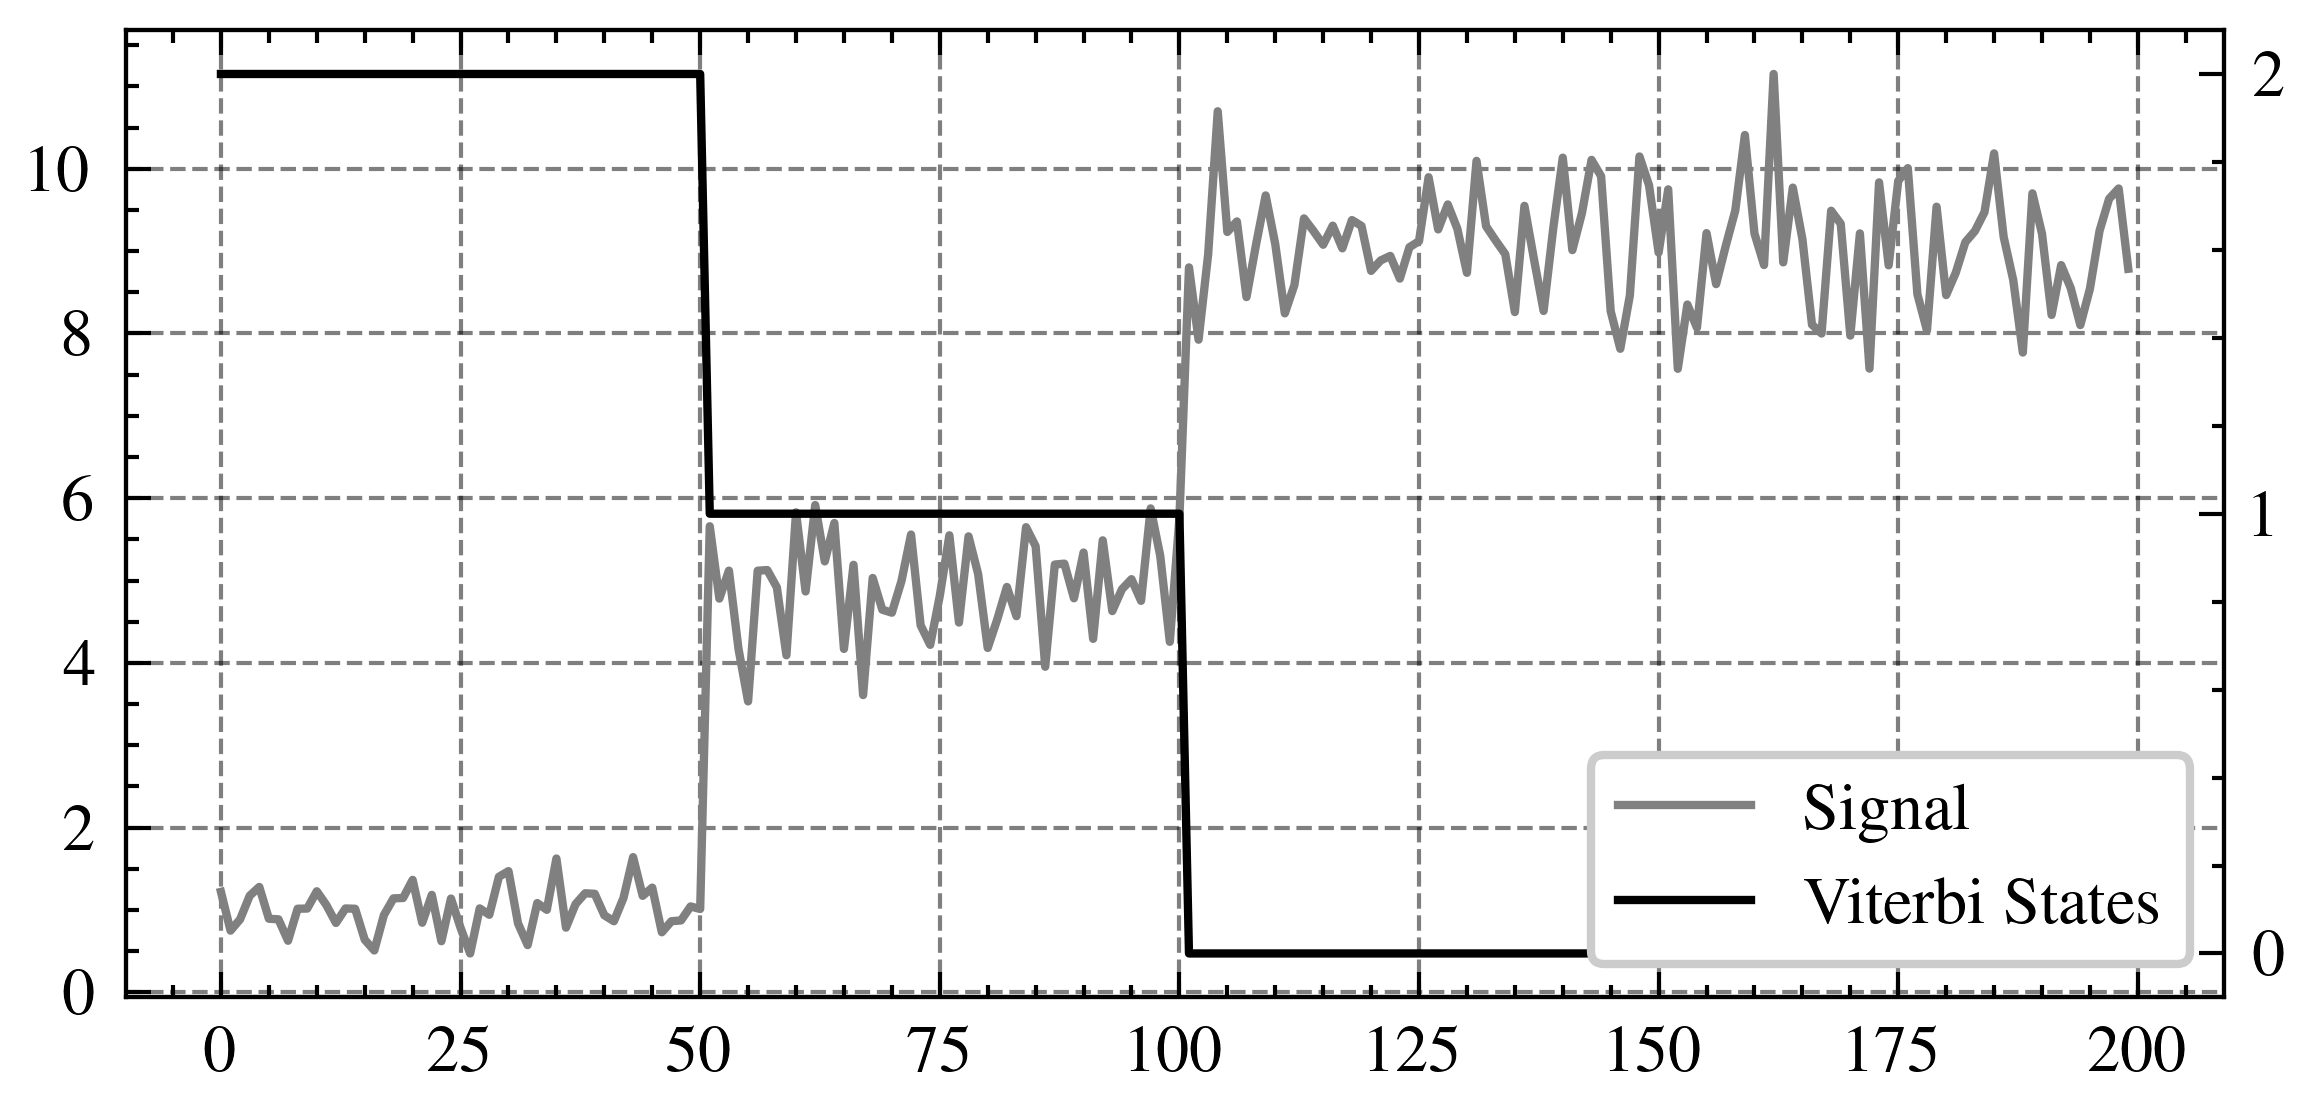

Recovered Means:
 [[9.07033373]
 [4.92006629]
 [1.00851924]]

Recovered Transition Matrix:
 [[1.00000000e+000 2.32928569e-033 6.20202987e-107]
 [2.00000070e-002 9.79999993e-001 1.93590814e-029]
 [1.30099875e-081 1.96078431e-002 9.80392157e-001]]


In [106]:
# 5. Visualization
fig = plt.figure(figsize=(4, 2))
ax = fig.add_subplot(111)
ax.plot(x, color='gray', alpha=1, label="Observed Signal")
ax2 = ax.twinx()
ax2.plot([],[], color="gray")
ax2.plot([],[],color="k", linestyle="-")
ax2.legend(["Signal", "Viterbi States"], loc="lower right")
ax2.plot(estimated_states, alpha=1, color="black", linestyle="-")
# ax2.plot(my_states, alpha=1, color="blue", linestyle="-")

# ax.set_yticks(np.arange(0,8,1))
ax2.set_yticks(np.arange(0, num_states, 1))
ax2.grid(False)


plt.tight_layout()
plt.show()

# Print recovered parameters
print("Recovered Means:\n", train_model.means_)
print("\nRecovered Transition Matrix:\n", train_model.transmat_)